# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
import tensorflow as tf
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
from keras import layers, models

I0000 00:00:1794164264.657544   82600 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

In [3]:
data = np.load(data_path)

In [4]:
train_images = data['train_images']
train_labels = data['train_labels']
val_images   = data['val_images']
val_labels   = data['val_labels']
test_images  = data['test_images']
test_labels  = data['test_labels']

In [5]:
train_images.shape, train_labels.shape, val_images.shape, val_labels.shape, test_images.shape, test_labels.shape

((11959, 28, 28, 3),
 (11959, 1),
 (1712, 28, 28, 3),
 (1712, 1),
 (3421, 28, 28, 3),
 (3421, 1))

In [6]:
print(f"ilosc obrazow train: {len(train_images)}")
print(f"ilosc obrazow test: {len(test_images)}")
print(f"ilosc obrazow val: {len(val_images)}")

ilosc obrazow train: 11959
ilosc obrazow test: 3421
ilosc obrazow val: 1712


6


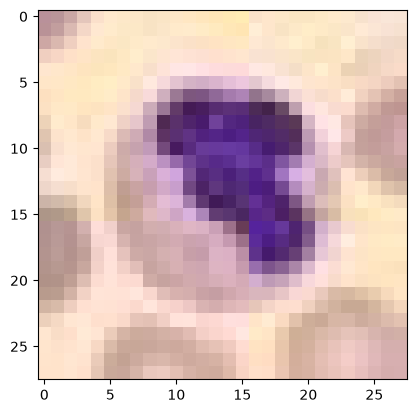

In [7]:
# plot zdjecia
i = 2
plt.imshow(train_images[i])
print(train_labels[i][0])

In [ ]:
train_images = train_images.astype("float32") / 255.0 # normalizacja obrazów do zakresu [0, 1]
val_images   = val_images.astype("float32") / 255.0
test_images  = test_images.astype("float32") / 255.0
num_classes = len(np.unique(train_labels))

## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

In [9]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(28, 28, 3)),
    layers.BatchNormalization(), # Ustawia średnią wyjść blisko 0 i odchylenie blisko 1, co stabilizuje proces uczenia.
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)), # Redukuje wymiary danych, zmniejszając liczbę parametrów i obliczeń. Pomaga w uniknięciu przeuczenia i zmniejsza model. Jakby tego nie dać model by zamiast 1.5 mb ważył ponad 25. Dzieli obraz na 2x2 i wybiera max wartość z tego okna.
    layers.Dropout(0.25), # randomowe wyłączanie 25% neuronów w warstwie podczas treningu, co pomaga w uniknięciu przeuczenia.

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(), 
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax')
])

/home/marek/Dokumenty/Rekrutacja-AI-Med-2026-2027/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1794164267.882698   82600 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4605 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5


In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy', # uzywane gdy mamy na wyjsciu liczby calkowite reprezentujace klasy, a nie wektory one-hot. W tym przypadku, etykiety są liczbami całkowitymi reprezentującymi klasy (0-8), więc używamy sparse_categorical_crossentropy.
    metrics=['accuracy']
)

In [11]:
model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True), # wylaczenie treningu jesli przez 10 epok nie poprawi sie wartosc val_loss. Przywraca najlepsze wagi modelu z epoki, w której osiągnięto najniższą wartość val_loss.
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6) # zmniejsza współczynnik uczenia o połowę, jeśli przez 3 epoki nie poprawi się wartość val_loss. Pomaga to w dalszym dopasowywaniu modelu, gdy zbliża się do minimum funkcji straty.
]

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 469,416 (1.79 MB)

 Trainable params: 468,776 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)

In [12]:
history = model.fit(
    train_images, train_labels,
    epochs=50,
    batch_size=64,
    validation_data=(val_images, val_labels), # uzywanie walidacji w trakcie treningu pozwala na monitorowanie wydajności modelu na danych, których nie widział podczas uczenia. Pomaga to w wykrywaniu przeuczenia i dostosowywaniu hiperparametrów.
    callbacks=callbacks
)

Epoch 1/50


I0000 00:00:1794164272.541867   82667 service.cc:153] XLA service 0x7fdfdc163ec0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794164272.541888   82667 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce GTX 1660 Ti, Compute Capability 7.5 (Driver: 13.4.0; Runtime: 13.0.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794164272.632924   82667 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794164273.261836   82667 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1794164273.448012   82667 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4698__.63


 24/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5098 - loss: 1.5645

I0000 00:00:1794164283.635516   82667 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


180/187 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7549 - loss: 0.7319

I0000 00:00:1794164285.680864   82668 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4698__.63


187/187 ━━━━━━━━━━━━━━━━━━━━ 30s 86ms/step - accuracy: 0.7581 - loss: 0.7203 - val_accuracy: 0.1373 - val_loss: 9.3307 - learning_rate: 0.0010
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8609 - loss: 0.3885 - val_accuracy: 0.2564 - val_loss: 4.9696 - learning_rate: 0.0010
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8894 - loss: 0.3084 - val_accuracy: 0.5012 - val_loss: 1.7971 - learning_rate: 0.0010
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9017 - loss: 0.2725 - val_accuracy: 0.8014 - val_loss: 0.5572 - learning_rate: 0.0010
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9150 - loss: 0.2395 - val_accuracy: 0.8230 - val_loss: 0.4822 - learning_rate: 0.0010
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9226 - loss: 0.2159 - val_accuracy: 0.7564 - val_loss: 0.7248 - learning_rate: 0.0010
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9247 - loss: 0.2028 - val_accur

Cnn
* Ekstrakcja cech - pierwsze warstwy wykrywają podstawowe krawędzie oraz kontury komórek, a kolejne łączą je w bardziej złożone struktury biologiczne
* BatchNormalization - normalizuje aktywacje wewnątrz sieci (średnia okolo 0, odchylenie standardowe okolo 1)
* Dropout - losowo zeruje wybrany odsetek połączeń w trakcie treningu chroniąc przed przeuczeniem
* MaxPooling2D - redukują rozdzielczość map z 28x28 do 14x14 do 7x7
* Flatten - spłaszcza mapy cech do postaci 1D (array liczb)

Koszt
sparse_categorical_crossentropy - wybrano ponieważ etykiety klas w zbiorze danych reprezentowane są jako pojedyncze liczby całkowite

Optymalizator
Adam - lr = 0.001 pozwala na szybkie wpadniece w dolek optymalizacyjny

Walidacja i mechanizmy zatrzymania
val_images, val_labels - służy do ocenienia jakosci modelu na danych na których nie jest trenowany
EarlyStopping - śledzi wartość val_loss. Jeśli błąd walidacyjny nie maleje przez 10 kolejnych epok (patience=10), trening zostaje przerwany z najlepszymi wagami
ReduceLROnPlateau - zmniejsza lr o połowę gdy błąd walidacyny utknie.

Zbiory
test_images, test_labels - przez cały proces były odizolowane

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

In [13]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"Dokładność: {test_acc * 100}%")

107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.9614 - loss: 0.1266
Dokładność: 96.14148139953613%


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [15]:
y_pred = np.argmax(model.predict(test_images), axis=1)

107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step


In [16]:
print(classification_report(test_labels, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.92      0.95       244
           1       1.00      1.00      1.00       624
           2       0.97      0.96      0.97       311
           3       0.90      0.93      0.91       579
           4       0.95      0.93      0.94       243
           5       0.93      0.93      0.93       284
           6       0.97      0.97      0.97       666
           7       1.00      1.00      1.00       470

    accuracy                           0.96      3421
   macro avg       0.96      0.95      0.96      3421
weighted avg       0.96      0.96      0.96      3421



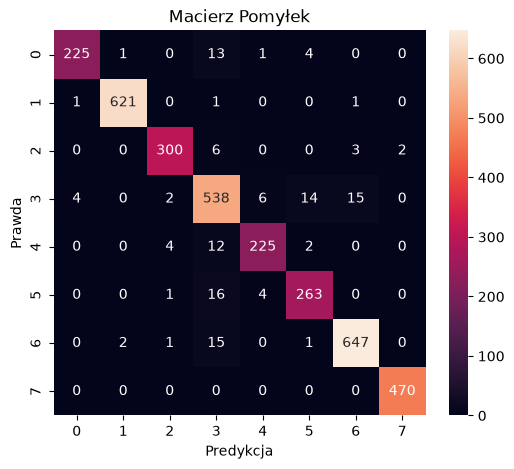

In [17]:
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(test_labels, y_pred), annot=True, fmt='d')
plt.xlabel('Predykcja')
plt.ylabel('Prawda')
plt.title('Macierz Pomyłek')
plt.show()

In [18]:
conv_layers = []
for layer in model.layers:
    if 'conv' in layer.name:
        conv_layers.append(layer)
last_conv_layer = conv_layers[-1]
activation_model = tf.keras.models.Model(inputs=model.inputs, outputs=last_conv_layer.output)

[dokumentacja na podstawie ktorej zrobione zostalo wyswietlanie danych](https://keras.io/examples/vision/visualizing_what_convnets_learn/)

In [19]:
last_conv_layer_name = [l.name for l in model.layers if 'conv' in l.name][-1]

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    
    pooled_grads = tf.reduce_mean(grads)

    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = np.sum(last_conv_layer_output * pooled_grads, axis=-1)
    heatmap = np.squeeze(heatmap)

    heatmap = np.maximum(heatmap, 0)
    if np.max(heatmap) != 0:
        heatmap /= np.max(heatmap)

    return heatmap

In [20]:

def pokaz_wyjasnienie(index):
    img = test_images[index]
    true_label = test_labels.flatten()[index]
    pred_label = y_pred[index]
    
    activations = activation_model.predict(np.expand_dims(img, axis=0), verbose=0)[0] 
    heatmap = np.mean(activations, axis=-1)

    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    
    axes[0].imshow(img)
    axes[0].set_title(f"oryginal: {true_label}, predykcja: {pred_label}")
    axes[0].axis('off')
    
    axes[1].imshow(heatmap, cmap='jet')
    axes[1].set_title("aktywacja")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()


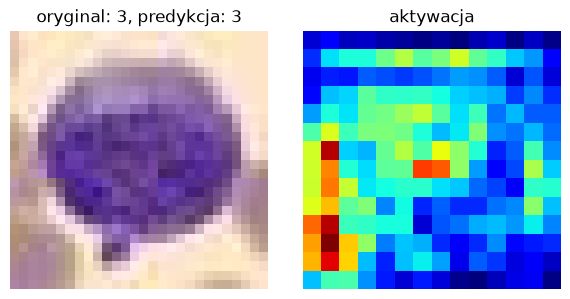

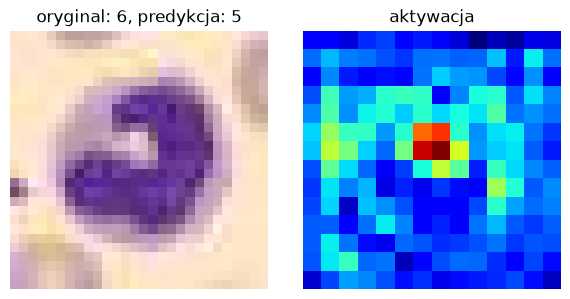

In [21]:
poprawne_idx = np.where(y_pred == test_labels.flatten())[0]
pokaz_wyjasnienie(poprawne_idx[0])

bledne_idx = np.where(y_pred != test_labels.flatten())[0]
if len(bledne_idx) > 0:
    pokaz_wyjasnienie(bledne_idx[0])

## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.

Źródła:
* https://machinelearningmastery.com/three-ways-to-build-machine-learning-models-in-keras/
* Gemini (Pomoc przy optymalizacji struktury sieci CNN (dobór `MaxPooling2D`, `BatchNormalization`, `Dropout`), naprawie błędów spójności wymiarów NumPy (`ValueError: broadcasting`) oraz przygotowaniu czystego kodu wizualizacji wyjaśnień.)
* Github Copilot